In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_log_error, mean_squared_error, r2_score
from sklearn.feature_selection import SequentialFeatureSelector
from scipy.stats import probplot

from pathlib import Path
folder = Path(r'C:\Users\tsher\OneDrive\Desktop\National University\Classes\DDS-8555\Assignment-3\playground-series-s4e4')
train = pd.read_csv(folder / ('train(1).csv' if (folder / 'train(1).csv').exists() else 'train.csv'))
test = pd.read_csv(folder / 'test.csv')
sample = pd.read_csv(folder / 'sample_submission.csv')
X = pd.get_dummies(train.drop(columns=['id','Rings']), dtype=float)
T = pd.get_dummies(test.drop(columns=['id']), dtype=float).reindex(columns=X.columns, fill_value=0)
y = train['Rings']
Xtr, Xval, ytr, yval = train_test_split(X, y, test_size=.2, random_state=42)
print(train.shape, test.shape, train.isna().sum().sum())

(90615, 10) (60411, 9) 0


In [2]:
models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=10)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=.01, max_iter=10000)),
    'ElasticNet': make_pipeline(StandardScaler(), ElasticNet(alpha=.01, l1_ratio=.5, max_iter=10000))
}
scores = {}
for name, model in models.items():
    model.fit(Xtr, ytr)
    pred = np.maximum(model.predict(Xval), 0)
    scores[name] = np.sqrt(mean_squared_log_error(yval, pred))
print(pd.Series(scores).sort_values())
print(pd.Series(models['Lasso'][-1].coef_, index=X.columns).sort_values(key=abs, ascending=False))

ElasticNet    0.166484
Lasso         0.166724
Ridge         0.166762
dtype: float64
Shell weight      2.904024
Whole weight.1   -2.828183
Whole weight      0.800449
Height            0.756070
Diameter          0.534473
Sex_I            -0.329653
Whole weight.2   -0.307634
Sex_F             0.004470
Length            0.000000
Sex_M             0.000000
dtype: float64


In [3]:
# Forward subset selection among the five strongest Lasso predictors
important = pd.Series(abs(models['Lasso'][-1].coef_), index=X.columns).nlargest(5).index.tolist()
selector = SequentialFeatureSelector(LinearRegression(), n_features_to_select=3, direction='forward', cv=3, n_jobs=-1)
selector.fit(Xtr[important], ytr)
chosen = list(pd.Index(important)[selector.get_support()])
subset = LinearRegression().fit(Xtr[chosen], ytr)
pred = np.maximum(subset.predict(Xval[chosen]), 0)
scores['Subset'] = np.sqrt(mean_squared_log_error(yval, pred))
print('Selected:', chosen, 'RMSLE:', scores['Subset'])

Selected: ['Shell weight', 'Whole weight.1', 'Height'] RMSLE: 0.17007953425585767


In [4]:
pcr = GridSearchCV(make_pipeline(StandardScaler(), PCA(), LinearRegression()),
                   {'pca__n_components': list(range(1, min(X.shape[1], 12) + 1))},
                   cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
pcr.fit(Xtr, ytr)
pred = np.maximum(pcr.predict(Xval), 0)
scores['PCR'] = np.sqrt(mean_squared_log_error(yval, pred))
print('PCR components:', pcr.best_params_)
print(pd.Series(scores).sort_values())

PCR components: {'pca__n_components': 9}
ElasticNet    0.166484
Lasso         0.166724
Ridge         0.166762
PCR           0.166774
Subset        0.170080
dtype: float64


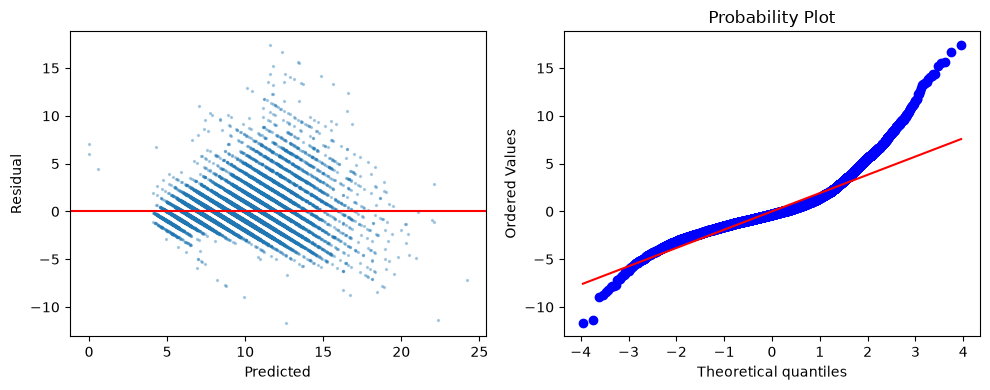

Best: ElasticNet R2: 0.5988676851330901 RMSE: 2.029919684552314
      id      Rings
0  90615   8.915553
1  90616  10.165535
2  90617  10.336647
3  90618  10.766806
4  90619   7.750298


In [5]:
best = min(scores, key=scores.get)
model = pcr.best_estimator_ if best == 'PCR' else subset if best == 'Subset' else models[best]
pred = model.predict(Xval[chosen] if best == 'Subset' else Xval)
residuals = yval - pred
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(pred, residuals, s=2, alpha=.3)
ax[0].axhline(0, color='red'); ax[0].set(xlabel='Predicted', ylabel='Residual')
probplot(residuals, dist='norm', plot=ax[1]); plt.tight_layout(); plt.show()
print('Best:', best, 'R2:', r2_score(yval, pred), 'RMSE:', np.sqrt(mean_squared_error(yval, pred)))
model.fit(X[chosen] if best == 'Subset' else X, y)
submission = sample.copy()
submission['Rings'] = np.maximum(model.predict(T[chosen] if best == 'Subset' else T), 0)
submission.to_csv(folder / 'abalone_submission.csv', index=False)
print(submission.head())

In [6]:
# Second Kaggle submission: Principal Components Regression (PCR)
pcr_final = make_pipeline(StandardScaler(), PCA(n_components=pcr.best_params_['pca__n_components']), LinearRegression())
pcr_final.fit(X, y)
pcr_submission = sample.copy()
pcr_submission['Rings'] = np.maximum(pcr_final.predict(T), 0)
pcr_submission.to_csv(folder / 'abalone_pcr_submission.csv', index=False)
print('PCR submission saved:', folder / 'abalone_pcr_submission.csv')
print(pcr_submission.head())


PCR submission saved: C:\Users\tsher\OneDrive\Desktop\National University\Classes\DDS-8555\Assignment-3\playground-series-s4e4\abalone_pcr_submission.csv
      id      Rings
0  90615   8.535442
1  90616  10.029784
2  90617  10.305835
3  90618  10.956449
4  90619   7.782893


(c) Forward stepwise: Cp-best model has 4 predictors ['X2', 'X1', 'X3', 'X10'] (Cp = 0.947)
  Intercept = 1.053
  X2: -3.2410
  X1: 1.7756
  X3: 0.6119
  X10: 0.0003
(d) Backward stepwise: Cp-best model has 5 predictors ['X1', 'X2', 'X6', 'X7', 'X8'] (Cp = 0.964)
  Intercept = 1.012
  X1: 2.3324
  X2: -3.1566
  X6: -0.0916
  X7: 0.0267
  X8: 0.0205
(e) Lasso: lambda = 0.0065, intercept = 1.002
  X1: 1.8271
  X2: -3.0738
  X3: 0.5571
  X4: -0.0496
  X5: 0.0096
  X6: -0.0000
  X7: 0.0000
  X8: 0.0000
  X9: -0.0000
  X10: 0.0004


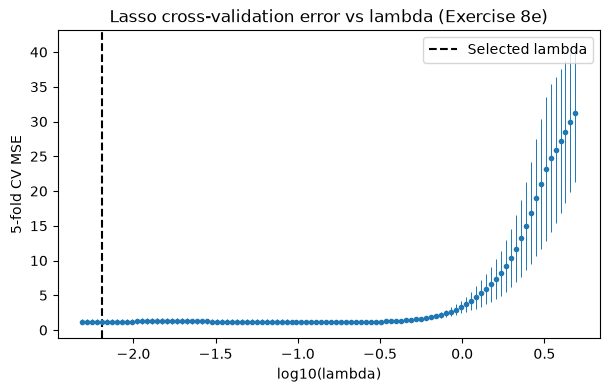

(f) Forward stepwise: Cp-best model has 3 predictors ['X7', 'X9', 'X4'] (Cp = 0.924)
  Intercept = 0.969
  X7: 7.0162
  X9: -0.0028
  X4: -0.0417
(f) Lasso: lambda = 0.9170, intercept = 1.179
  X1: -0.0000
  X2: -0.0000
  X3: 0.0000
  X4: -0.0000
  X5: 2.5332
  X6: -0.0000
  X7: 6.0470
  X8: -0.0000
  X9: 0.0816
  X10: -0.0000


,"max_iter max_iter: int, default=1000The maximum number of iterations.",100000
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as an argument.",'auto'
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, `X` will be copied; otherwise, it may be overwritten.",True
,"verbose verbose: bool or int, default=FalseAmount of verbosity.",False
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [7]:
# ============================================================
# ISLP Chapter 6, Applied Exercise 8 (p. 286)
# Forward / backward stepwise selection (Cp) and the lasso
# on simulated polynomial data
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold

# (a) Generate predictor X and noise vector eps, n = 100
rng = np.random.default_rng(1)
n = 100
X = rng.normal(size=n)
eps = rng.normal(size=n)

# (b) Response Y = b0 + b1*X + b2*X^2 + b3*X^3 + eps
b0, b1, b2, b3 = 1, 2, -3, 0.5
Y = b0 + b1*X + b2*X**2 + b3*X**3 + eps

# Candidate predictors X, X^2, ..., X^10
D = pd.DataFrame({f'X{j}': X**j for j in range(1, 11)})

def rss(cols, y):
    """Residual sum of squares of an OLS fit on the given columns."""
    if not cols:
        return ((y - y.mean())**2).sum()
    m = LinearRegression().fit(D[cols], y)
    return ((y - m.predict(D[cols]))**2).sum()

def sigma2(y):
    """Error variance estimate from the full 10-predictor model."""
    return rss(list(D.columns), y) / (n - 10 - 1)

def cp(cols, y, s2):
    """Mallows' Cp = (RSS + 2*d*sigma^2) / n."""
    return (rss(cols, y) + 2*len(cols)*s2) / n

def forward(y):
    s2 = sigma2(y); sel = []; rem = list(D.columns)
    path = [([], cp([], y, s2))]
    while rem:
        best = min(rem, key=lambda c: rss(sel + [c], y))
        sel = sel + [best]; rem.remove(best)
        path.append((sel.copy(), cp(sel, y, s2)))
    return path

def backward(y):
    s2 = sigma2(y); sel = list(D.columns)
    path = [(sel.copy(), cp(sel, y, s2))]
    while sel:
        drop = min(sel, key=lambda c: rss([s for s in sel if s != c], y))
        sel = [s for s in sel if s != drop]
        path.append((sel.copy(), cp(sel, y, s2)))
    return path[::-1]

def report(path, y, label):
    """Print the Cp-best model and its coefficients."""
    cols, best_cp = min(path, key=lambda t: t[1])
    m = LinearRegression().fit(D[cols], y)
    print(f'{label}: Cp-best model has {len(cols)} predictors {cols} (Cp = {best_cp:.3f})')
    print(f'  Intercept = {m.intercept_:.3f}')
    for c, v in zip(cols, m.coef_):
        print(f'  {c}: {v:.4f}')
    return m

# (c) Forward stepwise selection with Cp
report(forward(Y), Y, '(c) Forward stepwise')

# (d) Backward stepwise selection with Cp
report(backward(Y), Y, '(d) Backward stepwise')

# (e) Lasso with 5-fold cross-validation
kf = KFold(5, shuffle=True, random_state=1)

def fit_lasso(y, label):
    pipe = make_pipeline(StandardScaler(),
                         LassoCV(cv=kf, max_iter=100000, random_state=0)).fit(D, y)
    las, sc = pipe[-1], pipe[0]
    coef = las.coef_ / sc.scale_                       # back to original scale
    intercept = las.intercept_ - np.sum(coef * sc.mean_)
    print(f'{label}: lambda = {las.alpha_:.4f}, intercept = {intercept:.3f}')
    for c, v in zip(D.columns, coef):
        print(f'  {c}: {v:.4f}')
    return las

las = fit_lasso(Y, '(e) Lasso')

# Plot of cross-validation error as a function of lambda
mse = las.mse_path_.mean(axis=1)
se = las.mse_path_.std(axis=1) / np.sqrt(5)
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(np.log10(las.alphas_), mse, yerr=se, fmt='o', ms=3, lw=0.7)
ax.axvline(np.log10(las.alpha_), ls='--', color='k', label='Selected lambda')
ax.set_xlabel('log10(lambda)'); ax.set_ylabel('5-fold CV MSE')
ax.set_title('Lasso cross-validation error vs lambda (Exercise 8e)')
ax.legend(); plt.show()

# (f) New response Y = b0 + b7*X^7 + eps; forward stepwise and lasso
b7 = 7
Y7 = b0 + b7*X**7 + eps
report(forward(Y7), Y7, '(f) Forward stepwise')
fit_lasso(Y7, '(f) Lasso')